# 2. Evolution and encrypted-AMP richness

Question: are particular clades enriched in qualifying encrypted AMP sequences
after accounting for screening exposure, proteome size and relatedness?

**Saved inferential results use simulated data.** Real published genus totals
and actual source-genome predictions are descriptive checks with explicit scope.

In [1]:
from pathlib import Path
import os, sys, json, platform, subprocess
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/genomespot_lens/amp_study.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from genomespot_lens.amp_study import (
    TRAITS, load_bundle, prepare_cohort, analysis_subset, standardized,
    fit_nb, effect_table, grouped_ecology_cv, tree_covariance,
    build_phylogenetic_nb,
)

# Explicit demonstration mode. Change to "real" only after preparing the contract.
# No automatic fallback to simulated data is permitted.
MODE = os.environ.get("AMP_STUDY_MODE", "demo")
assert MODE in {"demo", "real"}
COHORT = os.environ.get("AMP_STUDY_COHORT", "atb")
DATA_DIR = (ROOT / "examples/amp-study/demo") if MODE == "demo" else Path(
    os.environ.get("AMP_STUDY_DATA", str(ROOT / "data/amp-study")))
RUN_PHYLO_MCMC = os.environ.get("AMP_STUDY_PHYLO_MCMC", "0") == "1"
SEED = 23
LABEL = "SIMULATED DATA — software demonstration" if MODE == "demo" else "REAL COHORT — observational associations"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
display(Markdown(f"**{LABEL}**"))
print("Python", platform.python_version(), "| cohort:", COHORT, "| bundle:", "examples/amp-study/demo" if MODE == "demo" else DATA_DIR.name)
FIG_DIR = ROOT / "runs/amp-study/figures" / MODE
FIG_DIR.mkdir(parents=True, exist_ok=True)
def save_figure(figure, name):
    figure.savefig(FIG_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    figure.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight")

**SIMULATED DATA — software demonstration**

Python 3.11.16 | cohort: atb | bundle: examples/amp-study/demo


In [2]:
# Actual published-source audit, independent of the simulated analysis below.
source_audit = json.loads((ROOT / "examples/amp-study/source-audit.json").read_text())
display(pd.DataFrame([
    {"source": "Archaeome complete positive-score catalog", "records": source_audit["archaeome"]["score_rows"], "genome richness ready": False},
    {"source": "Archaeome selected source mappings", "records": source_audit["archaeome"]["selected_mapping_rows"], "genome richness ready": False},
]))
source_dir = ROOT / "examples/amp-study/source-genomes"
if source_dir.exists():
    # Genuine GenomeSPOT outputs. They are not joined to invented AMP counts.
    real_predictions = pd.read_csv(source_dir / "genomespot.csv")
    display(real_predictions[real_predictions.target.isin(TRAITS.values())])
reconstruction_dir = ROOT / "examples/amp-study/archaeome-reconstruction"
reconstruction = json.loads((reconstruction_dir / "audit.json").read_text())
display(pd.DataFrame({"reported": reconstruction["expected_counts"],
                      "reconstructed": reconstruction["observed_counts"]}))
source_taxa = pd.read_csv(reconstruction_dir / "source_taxa.csv")
display(source_taxa[["reviewed_protein_records", "distinct_screened_fragments",
                     "distinct_high_scoring_peptides"]].describe())
print("Actual reconstructed taxa:", len(source_taxa), "| zero catalog hits:",
      reconstruction["taxa_with_zero_catalog_hits"], "| all published positives map:",
      reconstruction["all_positive_peptides_mapped"])
print("These are source-taxon reviewed-protein screens; use verified assembly joins for genome models.")
batch_dir = ROOT / "examples/amp-study/reconstructed-genomes"
if (batch_dir / "prediction_audit.json").exists():
    batch = json.loads((batch_dir / "prediction_audit.json").read_text())
    display(pd.Series(batch["counts"], name="ACTUAL current-reference batch checks"))
    print("Actual GenomeSPOT prediction rows:", batch["prediction_rows"])
    print(batch["candidate_caveat"])
print("ATB Results and Methods disagree on the MIC selection rule; resolve before a real ATB run.")
print("Source-screen linkage: see study/source-search.md and study/data-contract.md")

,source,records,genome richness ready
0,Archaeome complete positive-score catalog,12623,False
1,Archaeome selected source mappings,265,False


,genome_id,target,value,error,is_novel,warning,units
0,GCF_000091665.1,temperature_optimum,78.66277683556687,7.414129,False,NaN,C
3,GCF_000091665.1,ph_optimum,5.653625708702203,1.278201,False,NaN,pH
6,GCF_000091665.1,salinity_optimum,1.3394815190900058,1.877941,True,NaN,% w/v NaCl
9,GCF_000091665.1,oxygen,not tolerant,0.999991,True,NaN,probability
10,GCF_000011105.1,temperature_optimum,91.07637426802242,5.791886,False,NaN,C
13,GCF_000011105.1,ph_optimum,6.599838846769681,0.960230,False,NaN,pH
16,GCF_000011105.1,salinity_optimum,0.3534652516594101,1.873083,False,NaN,% w/v NaCl
19,GCF_000011105.1,oxygen,not tolerant,0.997884,False,NaN,probability
20,GCF_000008665.1,temperature_optimum,83.06935213778993,6.773858,False,NaN,C
23,GCF_000008665.1,ph_optimum,6.49814827121021,1.009838,False,NaN,pH


,reported,reconstructed
protein_records,19710,19710
distinct_proteins,18677,18677
source_taxa,233,233
distinct_screened_fragments,193331608,193331608
positive_catalog_rows,12623,12623


,reviewed_protein_records,distinct_screened_fragments,distinct_high_scoring_peptides
count,233.000000,2.330000e+02,233.000000
mean,84.592275,9.493362e+05,60.309013
std,182.176665,2.007127e+06,171.256962
min,1.000000,1.500000e+01,0.000000
25%,1.000000,1.724300e+04,0.000000
50%,4.000000,5.637300e+04,0.000000
75%,118.000000,1.187098e+06,32.000000
max,1787.000000,1.948918e+07,1821.000000


Actual reconstructed taxa: 233 | zero catalog hits: 128 | all published positives map: True
These are source-taxon reviewed-protein screens; use verified assembly joins for genome models.


historical_sources_contained               52
historical_sources_exact_full_proteins     47
genome_qc_pass                            103
prediction_success                        138
all_four_primary_traits_unflagged          89
preliminary_historical_join_candidate      24
Name: ACTUAL current-reference batch checks, dtype: int64

Actual GenomeSPOT prediction rows: 1380
Preliminary join candidates still require documented taxonomy, independent habitat, a rooted archaeal tree, composition/coverage controls and a frozen analysis. Failed QC and flagged traits are retained, not set to zero.
ATB Results and Methods disagree on the MIC selection rule; resolve before a real ATB run.
Source-screen linkage: see study/source-search.md and study/data-contract.md


## A real published result that must not be overinterpreted

The archaeome paper's Supplementary Table 1 contains the ten genera with the
highest and ten with the lowest reported active-EP counts, along with NCBI gene
totals. This is an outcome-selected genus sample. It cannot support an unbiased
genome-level regression or establish screening effort. Historical names are
preserved; taxonomic harmonization requires a separate explicit mapping.

In [3]:
published = pd.read_csv(ROOT / "examples/amp-study/published_genus_table.csv")
display(published)
assert len(published) == 20
print("Selected published genus rows only; no significance test is fitted to this table.")

,genus_as_published,active_eps,ncbi_gene_count,selection
0,Pyrococcus,2184,20225,published top/bottom ten genera
1,Methanocaldococcus,1822,12856,published top/bottom ten genera
2,Pyrobaculum,1749,19067,published top/bottom ten genera
3,Sulfolobus,1181,38170,published top/bottom ten genera
4,Thermococcus,881,94875,published top/bottom ten genera
5,Methanococcus,636,26682,published top/bottom ten genera
6,Archaeoglobus,541,13166,published top/bottom ten genera
7,Aeropyrum,460,3888,published top/bottom ten genera
8,Saccharolobus,442,120015,published top/bottom ten genera
9,Staphylothermus,412,3638,published top/bottom ten genera


Selected published genus rows only; no significance test is fitted to this table.


The biological unit is a genome. AMP richness counts **distinct peptide sequences
per genome**, after exact parent/source mapping and a complete scoring panel.
The exposure counts the corresponding distinct sequences screened under one
fixed protocol, model version and target panel. Missing or failed screens remain
missing. Repeated parent copies and multiple target scores do not multiply counts.

Use each dataset/cohort separately. ATB's Results report any-target <80 µM, while Methods say median-panel ≤80 µM;
that conflict needs resolution before a real ATB analysis. The demo illustrates
an any-target rule. The archaeome study uses a separate mean-panel ≤100 µM rule. Preserve the
original rule in `bundle.json`; harmonizing thresholds also requires harmonized
screening and source coverage. Predicted MIC and measured MIC are distinct fields.

In [4]:
tables, spec, provenance, tree_path = load_bundle(DATA_DIR, COHORT, expected_kind=MODE)
cohort, candidate_table, hit_audit = prepare_cohort(tables, spec)
display(pd.Series(hit_audit, name="hit-table audit"))
display(pd.DataFrame({
    "genomes": [len(cohort)],
    "completed_screens": [int(cohort.screen_eligible.sum())],
    "quality_pass": [int(cohort.genome_qc_pass.sum())],
    "all_four_traits_unflagged": [int(cohort.all_traits_unflagged.sum())],
    "amr_successful": [int(cohort.amr_status.eq("PASS").sum())],
}))
assert not cohort.loc[~cohort.screen_eligible, "amp_count"].notna().any()
assert not cohort.loc[~cohort.amr_status.eq("PASS"), "amr_gene_count"].notna().any()

input_rows                            8776
nonexact_rows_excluded                   0
incomplete_panel_peptides_excluded       0
distinct_genome_peptide_hits          4388
Name: hit-table audit, dtype: int64

,genomes,completed_screens,quality_pass,all_four_traits_unflagged,amr_successful
0,384,376,373,374,375


## Taxonomic coverage and descriptive rates

Count genomes, families and species before looking for enriched clades. Raw
ratios are descriptive; modeling uses counts and exposure offsets. Use an
outcome-independent balanced sampling design and avoid selecting clades for
testing merely because they have the largest observed counts.

,genomes,species,amp_count,screened,amps_per_100000_screened
phylum,,,,,
SIM_Phylum_0,119,16,1706.0,8826493,19.328175
SIM_Phylum_1,120,16,1288.0,8988018,14.330189
SIM_Phylum_2,118,16,1090.0,8513993,12.802454


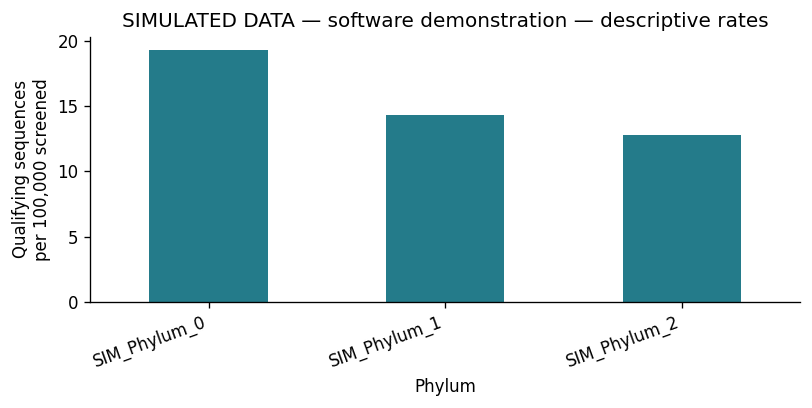

In [5]:
data, excluded = analysis_subset(cohort, require_traits=True)
data, scales = standardized(data, [f"trait_{t}" for t in TRAITS] + ["gc_fraction", "log_proteome_aa"])
clades = data.groupby("phylum").agg(genomes=("genome_id", "size"), species=("species", "nunique"), amp_count=("amp_count", "sum"), screened=("n_screened", "sum"))
clades["amps_per_100000_screened"] = 100000 * clades.amp_count / clades.screened
display(clades)
assert (clades.genomes >= 10).all(), "Prespecify handling of sparsely sampled clades"
ax = clades.amps_per_100000_screened.plot.bar(color="#247b8a", figsize=(7, 3.5))
ax.set(ylabel="Qualifying sequences\nper 100,000 screened", xlabel="Phylum", title=LABEL + " — descriptive rates")
plt.xticks(rotation=20, ha="right")
plt.tight_layout(); save_figure(plt.gcf(), "evolution_rates"); plt.show()

## Initial clade model

Compare phyla relative to an explicit reference clade, adjusting for ecology,
proteome size, GC and habitat. Species-clustered intervals are useful as an
initial taxonomic analysis. They do not replace the phylogenetic mixed model.
Adjust the clade contrast family for multiple testing. Repeat at other ranks
only as prespecified sensitivity analyses with appropriate multiplicity control.

In [6]:
clade_formula = "amp_count ~ C(phylum) + z_log_proteome_aa + z_gc_fraction + z_trait_temperature + z_trait_ph + z_trait_salinity + z_trait_oxygen + C(habitat)"
clade_fit = fit_nb(data, clade_formula)
clade_effects = effect_table(clade_fit, [x for x in clade_fit.params.index if x.startswith("C(phylum)")])
display(clade_effects)
print("Reference phylum:", sorted(data.phylum.unique())[0])

,term,log_rate_ratio,rate_ratio,ci_low,ci_high,p_value,q_value_bh
0,C(phylum)[T.SIM_Phylum_1],-0.312439,0.731660,0.512759,1.044013,0.084978,0.114781
1,C(phylum)[T.SIM_Phylum_2],-0.267499,0.765291,0.548842,1.067102,0.114781,0.114781


Reference phylum: SIM_Phylum_0


## Primary relatedness model

Let `C` be Brownian shared-branch covariance from the explicitly rooted tree,
normalized to a unit diagonal. Fit `log(mu) = log(exposure/100000) + X beta + u`,
where `u ~ Normal(0, sigma_phylo² C)` and counts follow a negative binomial.
`X` includes the clade contrasts, proteome size, GC, ecology and habitat. Clade
effects and the phylogenetic effect can be weakly identified; report uncertainty
and prior sensitivity. A taxonomy label, cluster-robust standard error or
dendrogram alone is not a phylogenetic adjustment.

Run bacteria and archaea separately with appropriate marker trees. The ATB
bacterial marker tree is not a valid archaeal tree. This implementation checks
unique tips, exact sample alignment and finite nonnegative branch lengths, and
limits dense covariance to 500 genomes. Root choice is an assumption to test.

In [7]:
import patsy
import pymc as pm
if not spec.get("tree_rooted"):
    raise ValueError("A documented rooted tree with branch lengths is required")
phylo_cov = tree_covariance(tree_path, data.genome_id.tolist())
X_phylo = patsy.dmatrix('1 + C(phylum) + z_log_proteome_aa + z_gc_fraction + z_trait_temperature + z_trait_ph + z_trait_salinity + z_trait_oxygen + C(habitat)', data, return_type="dataframe", NA_action="raise")
phylo_model = build_phylogenetic_nb(data, X_phylo, phylo_cov)
print("Built phylogenetic negative-binomial model:", len(data), "genomes,", X_phylo.shape[1], "fixed effects")
# A prior-predictive check exercises the actual mixed-model likelihood.
with phylo_model:
    prior_check = pm.sample_prior_predictive(samples=20, random_seed=SEED, var_names=["amp_count"])
print("Prior predictive dimensions:", dict(prior_check.prior_predictive.sizes))
if RUN_PHYLO_MCMC:
    import arviz as az
    with phylo_model:
        phylo_fit = pm.sample(draws=1000, tune=1000, chains=4, cores=2,
                              target_accept=.95, random_seed=SEED,
                              idata_kwargs={"log_likelihood": True})
        posterior_check = pm.sample_posterior_predictive(phylo_fit, random_seed=SEED)
    diagnostics = az.summary(phylo_fit, var_names=["beta", "phylo_sd", "nb_shape"])
    display(diagnostics)
    print("Divergences:", int(phylo_fit.sample_stats.diverging.sum()))
    all_rhat = float(az.rhat(phylo_fit).to_array().max())
    min_bulk_ess = float(az.ess(phylo_fit, method="bulk").to_array().min())
    print("All-parameter maximum R-hat:", all_rhat, "| minimum bulk ESS:", min_bulk_ess)
    az.plot_ppc(posterior_check, num_pp_samples=50)
    plt.suptitle(LABEL + " — posterior predictive check")
    plt.show()
    assert all_rhat < 1.01, "Chains have not converged"
    assert min_bulk_ess >= 400, "Insufficient effective samples"
    assert int(phylo_fit.sample_stats.diverging.sum()) == 0, "Resolve divergences"
    draws = phylo_fit.posterior.beta.stack(sample=("chain", "draw"))
    posterior_effects = pd.DataFrame({
        "coefficient": X_phylo.columns,
        "rate_ratio_median": np.exp(draws.median("sample").values),
        "rate_ratio_q025": np.exp(draws.quantile(.025, dim="sample").values),
        "rate_ratio_q975": np.exp(draws.quantile(.975, dim="sample").values),
    })
    display(posterior_effects)
    (ROOT / "runs").mkdir(exist_ok=True)
    phylo_fit.to_netcdf(ROOT / "runs" / ("evolution_phylo_" + MODE + ".nc"))
    posterior_effects.to_csv(ROOT / "runs" / ("evolution_phylo_effects_" + MODE + ".csv"), index=False)
else:
    print("Posterior MCMC was NOT run. Enable AMP_STUDY_PHYLO_MCMC=1 for posterior estimates.")

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Built phylogenetic negative-binomial model: 357 genomes, 11 fixed effects


Sampling: [amp_count, beta, nb_shape, phylo_sd, phylo_z]


Prior predictive dimensions: {'chain': 1, 'draw': 20, 'genome': 357}
Posterior MCMC was NOT run. Enable AMP_STUDY_PHYLO_MCMC=1 for posterior estimates.


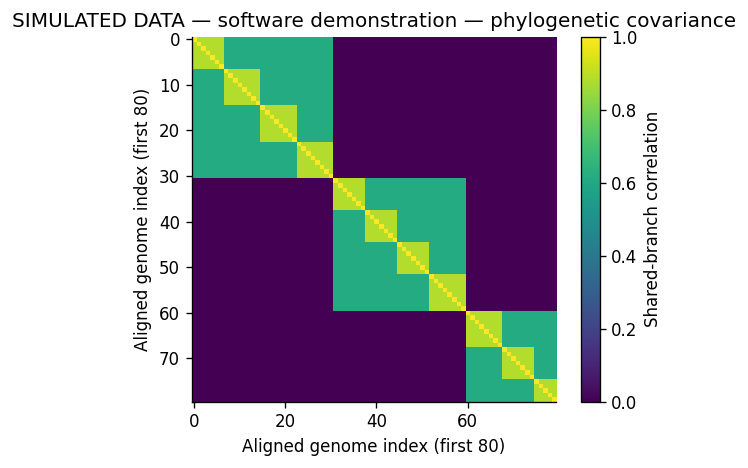

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(phylo_cov[:80, :80], vmin=0, vmax=1, cmap="viridis")
fig.colorbar(image, ax=ax, label="Shared-branch correlation")
ax.set(title=LABEL + " — phylogenetic covariance", xlabel="Aligned genome index (first 80)", ylabel="Aligned genome index (first 80)")
plt.tight_layout(); save_figure(fig, "evolution_covariance"); plt.show()

In [9]:
OUT = ROOT / "runs/amp-study/evolution" / MODE
OUT.mkdir(parents=True, exist_ok=True)
data.to_csv(OUT / "cohort.csv", index=False)
excluded.to_csv(OUT / "excluded.csv", index=False)
clades.reset_index().to_csv(OUT / "clade_coverage.csv", index=False)
clade_effects.to_csv(OUT / "clade_effects.csv", index=False)
provenance["analysis"] = "evolution"
provenance["seed"] = SEED
provenance["run_phylogenetic_mcmc"] = RUN_PHYLO_MCMC
provenance["git_commit"] = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
provenance["git_dirty"] = bool(subprocess.check_output(["git", "-C", str(ROOT), "status", "--porcelain"], text=True).strip())
provenance["bundle_settings"] = spec
provenance["packages"] = {p: version(p) for p in ["numpy", "pandas", "statsmodels", "pymc", "arviz", "biopython", "nbformat", "nbclient"]}
from genomespot_lens.core import sha256
provenance["analysis_code_sha256"] = {str(p.relative_to(ROOT)): sha256(p) for p in [ROOT / "src/genomespot_lens/amp_study.py", ROOT / "scripts/build_study_notebooks.py"]}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
print("Saved results:", OUT.relative_to(ROOT))
display(Markdown("**Demonstration complete; simulated coefficients are not biological findings.**"
                 if MODE == "demo" else "**Review diagnostics, exclusions and sensitivity analyses before interpreting associations.**"))

Saved results: runs/amp-study/evolution/demo


**Demonstration complete; simulated coefficients are not biological findings.**

## Evidence needed for an evolutionary conclusion

Replicate the clade comparison using an outcome-independent genome panel and
alternative plausible trees/rooting. Compare rates at equal screened sequence
coverage. Repeat within clades to check whether one species or heavily sequenced
lineage drives the result. Use posterior predictive checks and sampling
diagnostics before reporting phylogenetic posterior estimates. A clade association
alone does not demonstrate selection, ecological function or a particular gene
transfer mechanism. Published curated-protein coverage can vary strongly by clade.

Sources and methods:

- [GenomeSPOT paper](https://doi.org/10.1101/2024.03.22.586313)
- [AllTheBacteria paper](https://doi.org/10.1101/2024.03.08.584059)
- [Archaeome paper](https://doi.org/10.1038/s41564-025-02061-0) and
  [Mendeley data deposit](https://doi.org/10.17632/d8yzgtdrcp.3)
- [AMR annotation documentation](https://allthebacteria.org/docs/amr/)
- [ATB phylogeny documentation](https://allthebacteria.org/docs/phylogeny/)
- [Negative-binomial likelihood](https://www.pymc.io/projects/docs/en/v5.10.4/api/distributions/generated/pymc.NegativeBinomial.html)

See `study/data-contract.md`, `study/analysis-plan.md` and `study/source-search.md`
for input definitions, reproducibility, exclusions and remaining source gaps.